# Lab01 - sprint 1

## Random Variable 03 (r_def)

### Description

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Description (что такое центроид и r_def, смысл значений около 0 и 1, данные, почему величина случайная) -->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# константы
SEED = 42
N_REP = 100        # повторов на размер выборки (состоятельность)
N_SAMPLE = 1000    # размер выборки с возвращением / без
N_MC = 500         # повторов Монте-Карло для sd среднего
N_GOF = 2000       # подвыборка для goodness_of_fit
B_GOF = 200        # n_mc_samples для goodness_of_fit
K_CHI2 = 20        # число равновероятных интервалов для chi2
EPS = 1e-6         # обрезка 0 и 1

rng = np.random.default_rng(SEED)

In [2]:
df = pd.read_parquet("../wm811k_features.parquet")
x_all = df["r_def"]
x = x_all.dropna()
print("df.shape =", df.shape)
print("dieSize =", df["dieSize"].iloc[0], "| число лотов =", df["lotName"].nunique())
print(f"r_def определена: {len(x)} из {len(x_all)}, выпало {x_all.isna().mean():.4%}")
print("точных 0:", int((x == 0).sum()), "| точных 1:", int((x == 1).sum()))
print("n_defect == 1:", int((df["n_defect"] == 1).sum()), "| n_defect >= 2:", int((df["n_defect"] >= 2).sum()),
      "| min n_defect:", df["n_defect"].min())
x.describe()

df.shape = (15881, 11)
dieSize = 516.0 | число лотов = 715
r_def определена: 15881 из 15881, выпало 0.0000%
точных 0: 0 | точных 1: 0
n_defect == 1: 0 | n_defect >= 2: 15881 | min n_defect: 49


count    15881.000000
mean         0.070453
std          0.037101
min          0.001277
25%          0.042462
50%          0.066077
75%          0.093726
max          0.256344
Name: r_def, dtype: float64

#### Случайность: разброс внутри лотов

In [3]:
by_lot = df.dropna(subset=["r_def"]).groupby("lotName")["r_def"].agg(["count", "min", "max", "mean", "std"])
by_lot[by_lot["count"] >= 10].head(10)

,count,min,max,mean,std
lotName,,,,,
lot42869,23,0.003087,0.150390,0.068340,0.037052
lot42870,25,0.017336,0.159438,0.062587,0.033798
lot42871,21,0.009933,0.116662,0.064207,0.028393
lot42872,23,0.005161,0.164861,0.056299,0.037681
lot42873,21,0.010791,0.124241,0.056179,0.032151
lot42874,24,0.027964,0.137051,0.075958,0.028329
lot42875,23,0.027956,0.151073,0.071685,0.031173
lot42876,23,0.021081,0.122694,0.065492,0.023772
lot42877,25,0.020002,0.152667,0.070106,0.037416


In [4]:
# разложение дисперсии: внутри лотов и между лотами
g = df.dropna(subset=["r_def"]).groupby("lotName")["r_def"]
var_within = (g.var(ddof=1).fillna(0) * (g.size() - 1)).sum() / (len(x) - g.ngroups)
var_between = g.mean().var(ddof=1)
icc = var_between / (var_between + var_within)
pd.Series({"дисперсия всей выборки": x.var(ddof=1),
           "внутрилотовая компонента": var_within,
           "межлотовая компонента": var_between,
           "ICC": icc}).round(6)

дисперсия всей выборки      0.001376
внутрилотовая компонента    0.001334
межлотовая компонента       0.000102
ICC                         0.071074
dtype: float64

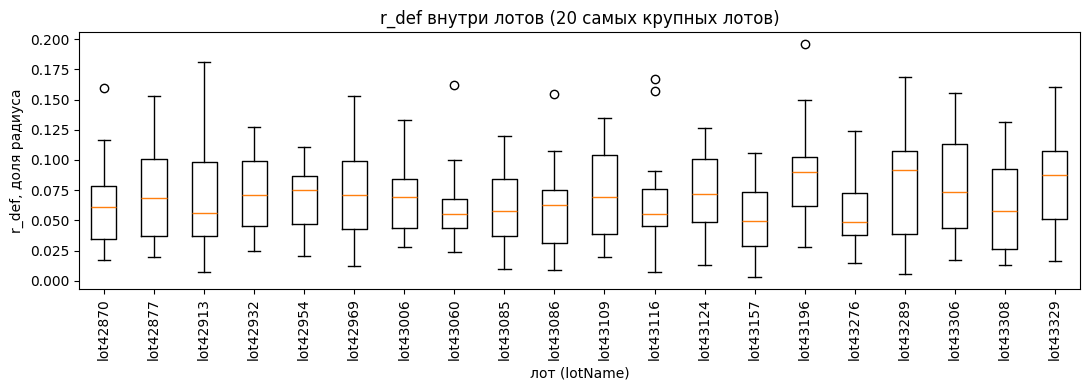

In [5]:
top = df["lotName"].value_counts().head(20).index
data = [df.loc[df["lotName"] == lot, "r_def"].dropna().values for lot in top]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(data)
ax.set_xticks(range(1, len(top) + 1), top, rotation=90)
ax.set_xlabel("лот (lotName)")
ax.set_ylabel("r_def, доля радиуса")
ax.set_title("r_def внутри лотов (20 самых крупных лотов)")
plt.tight_layout()
plt.show()

### EDA & Distribution

#### Описательные статистики

In [6]:
xv = x.to_numpy()
N = len(xv)
pd.Series({
    "n": N, "среднее": xv.mean(), "дисперсия (ddof=1)": xv.var(ddof=1), "ст. отклонение": xv.std(ddof=1),
    "медиана": np.median(xv), "q05": np.quantile(xv, 0.05), "q25": np.quantile(xv, 0.25),
    "q75": np.quantile(xv, 0.75), "q95": np.quantile(xv, 0.95), "min": xv.min(), "max": xv.max(),
    "асимметрия": stats.skew(xv), "эксцесс (избыточный)": stats.kurtosis(xv),
}).round(5)

n                       15881.00000
среднее                     0.07045
дисперсия (ddof=1)          0.00138
ст. отклонение              0.03710
медиана                     0.06608
q05                         0.01802
q25                         0.04246
q75                         0.09373
q95                         0.13835
min                         0.00128
max                         0.25634
асимметрия                  0.66048
эксцесс (избыточный)        0.34166
dtype: float64

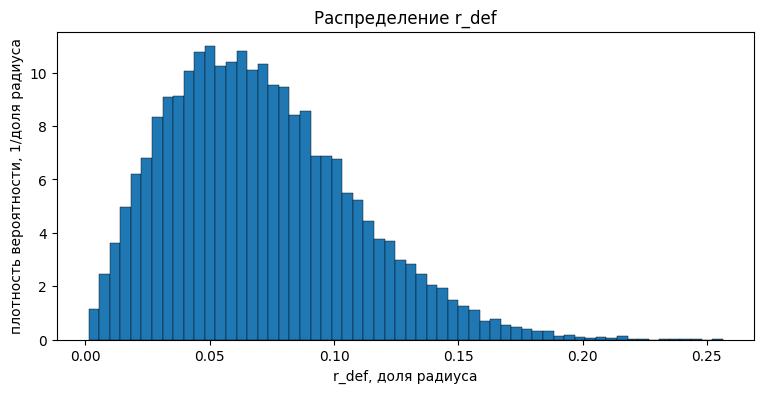

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(xv, bins=60, density=True, edgecolor="k", linewidth=0.3)
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title("Распределение r_def")
plt.show()

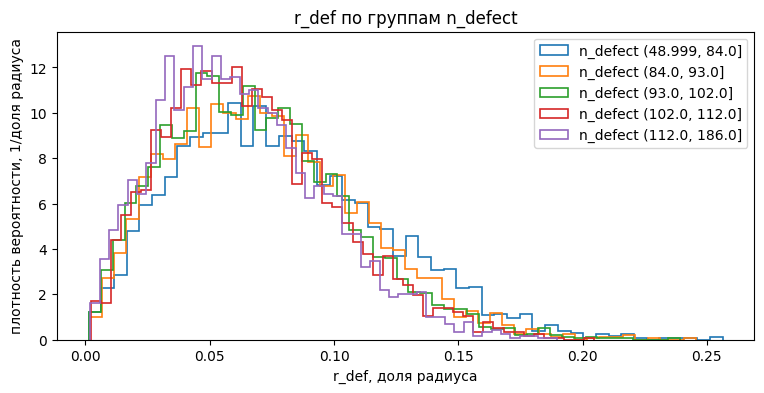

,count,mean,median,std
n_defect,,,,
"(48.999, 84.0]",3443,0.0791,0.0744,0.0413
"(84.0, 93.0]",3115,0.0731,0.0693,0.0378
"(93.0, 102.0]",3293,0.0693,0.0656,0.0362
"(102.0, 112.0]",2879,0.0666,0.0626,0.0341
"(112.0, 186.0]",3151,0.0630,0.0593,0.0327


In [8]:
# режимы по числу дефектов: случаев n_defect = 1 нет, группы по квинтилям n_defect
k_grp = pd.qcut(df.loc[x.index, "n_defect"], 5)
fig, ax = plt.subplots(figsize=(9, 4))
for grp, s in x.groupby(k_grp, observed=True):
    ax.hist(s, bins=50, density=True, histtype="step", lw=1.2, label=f"n_defect {grp}")
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title("r_def по группам n_defect")
ax.legend()
plt.show()
x.groupby(k_grp, observed=True).agg(["count", "mean", "median", "std"]).round(4)

#### Подгонка распределений

In [9]:
xc = np.clip(xv, EPS, 1 - EPS)
a_hat, b_hat, _, _ = stats.beta.fit(xc, floc=0, fscale=1)
_, s_ray = stats.rayleigh.fit(xv, floc=0)
c_wb, _, s_wb = stats.weibull_min.fit(xv, floc=0)

fits = {
    "бета": {"dist": stats.beta, "args": (a_hat, b_hat, 0, 1), "k": 2, "data": xc,
             "params": f"a={a_hat:.4f}, b={b_hat:.4f}"},
    "Рэлей": {"dist": stats.rayleigh, "args": (0, s_ray), "k": 1, "data": xv,
              "params": f"sigma={s_ray:.5f}"},
    "Вейбулл": {"dist": stats.weibull_min, "args": (c_wb, 0, s_wb), "k": 2, "data": xv,
                "params": f"c={c_wb:.4f}, lambda={s_wb:.5f}"},
}
for f in fits.values():
    f["ll"] = f["dist"].logpdf(f["data"], *f["args"]).sum()
    f["frozen"] = f["dist"](*f["args"])

fit_table = pd.DataFrame({name: {"параметры": f["params"], "число параметров": f["k"], "logL": f["ll"],
                                 "AIC": 2 * f["k"] - 2 * f["ll"],
                                 "среднее модели": f["frozen"].mean(), "1 - F(1)": f["frozen"].sf(1)}
                          for name, f in fits.items()}).T
fit_table["dAIC"] = fit_table["AIC"].astype(float) - fit_table["AIC"].astype(float).min()
fit_table

,параметры,число параметров,logL,AIC,среднее модели,1 - F(1),dAIC
бета,"a=2.9389, b=38.8312",2,30533.937203,-61063.874407,0.07036,0.0,305.465052
Рэлей,sigma=0.05630,1,30685.669729,-61369.339459,0.070565,0.0,0.000000
Вейбулл,"c=1.9857, lambda=0.07950",2,30686.344556,-61368.689112,0.070468,0.0,0.650347


In [10]:
# LR-тест: Рэлей (c = 2) вложен в Вейбулл
lr_rw = 2 * (fits["Вейбулл"]["ll"] - fits["Рэлей"]["ll"])
p_rw = stats.chi2.sf(lr_rw, df=1)
print(f"LR Рэлей vs Вейбулл = {lr_rw:.3f}, p = {p_rw:.3e}, c Вейбулла = {c_wb:.4f}")

LR Рэлей vs Вейбулл = 1.350, p = 2.453e-01, c Вейбулла = 1.9857


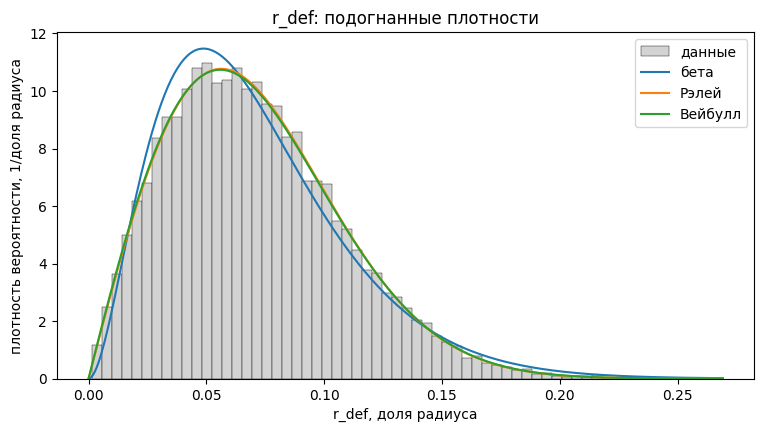

In [11]:
grid = np.linspace(0, xv.max() * 1.05, 400)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(xv, bins=60, density=True, color="lightgray", edgecolor="k", linewidth=0.3, label="данные")
for name, f in fits.items():
    ax.plot(grid, f["frozen"].pdf(grid), lw=1.5, label=name)
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности, 1/доля радиуса")
ax.set_title("r_def: подогнанные плотности")
ax.legend()
plt.show()

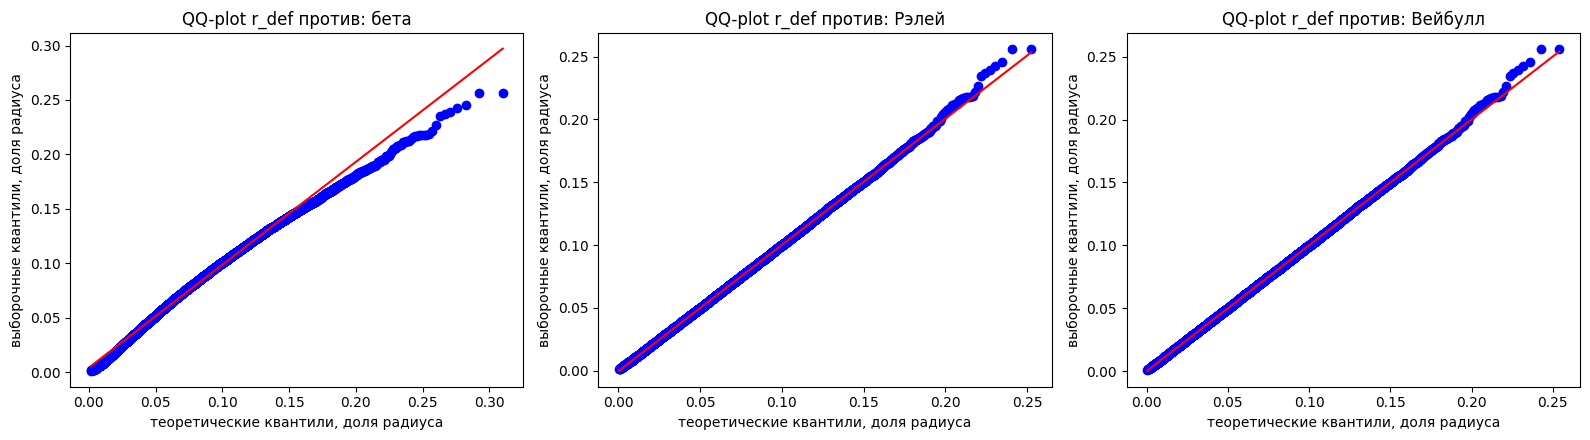

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, f) in zip(axes, fits.items()):
    stats.probplot(f["data"], dist=f["dist"], sparams=f["args"], plot=ax)
    ax.set_title(f"QQ-plot r_def против: {name}")
    ax.set_xlabel("теоретические квантили, доля радиуса")
    ax.set_ylabel("выборочные квантили, доля радиуса")
plt.tight_layout()
plt.show()

#### Теоретический эталон: равномерные дефекты

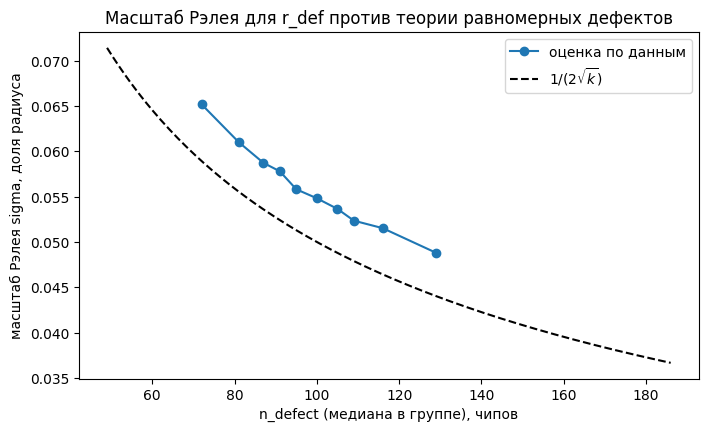

,группа n_defect,размер,медиана k,sigma Рэлея (ММП),теория 1/(2*sqrt(k)),отношение
0,"(48.999, 77.0]",1698,72.0,0.06518,0.05893,1.10616
1,"(77.0, 84.0]",1745,81.0,0.06102,0.05556,1.09836
2,"(84.0, 88.0]",1383,87.0,0.05874,0.05361,1.09569
3,"(88.0, 93.0]",1732,91.0,0.05780,0.05241,1.10270
4,"(93.0, 97.0]",1507,95.0,0.05581,0.05130,1.08803
5,"(97.0, 102.0]",1786,100.0,0.05482,0.05000,1.09642
6,"(102.0, 106.0]",1278,105.0,0.05365,0.04880,1.09952
7,"(106.0, 112.0]",1601,109.0,0.05235,0.04789,1.09311
8,"(112.0, 121.0]",1618,116.0,0.05153,0.04642,1.10989
9,"(121.0, 186.0]",1533,129.0,0.04880,0.04402,1.10856


In [13]:
# масштаб Рэлея по группам n_defect против 1/(2*sqrt(k))
kd = df.loc[x.index, "n_defect"]
grp = pd.qcut(kd, 10)
ray_rows = []
for gname, s in x.groupby(grp, observed=True):
    k_med = kd[s.index].median()
    ray_rows.append({"группа n_defect": str(gname), "размер": len(s), "медиана k": k_med,
                     "sigma Рэлея (ММП)": np.sqrt((s**2).mean() / 2),
                     "теория 1/(2*sqrt(k))": 1 / (2 * np.sqrt(k_med))})
ray_tab = pd.DataFrame(ray_rows)
ray_tab["отношение"] = ray_tab["sigma Рэлея (ММП)"] / ray_tab["теория 1/(2*sqrt(k))"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ray_tab["медиана k"], ray_tab["sigma Рэлея (ММП)"], "o-", label="оценка по данным")
kk = np.linspace(kd.min(), kd.max(), 200)
ax.plot(kk, 1 / (2 * np.sqrt(kk)), "k--", label=r"$1/(2\sqrt{k})$")
ax.set_xlabel("n_defect (медиана в группе), чипов")
ax.set_ylabel("масштаб Рэлея sigma, доля радиуса")
ax.set_title("Масштаб Рэлея для r_def против теории равномерных дефектов")
ax.legend()
plt.show()
ray_tab.round(5)

z: среднее = 1.3816 (Rayleigh(1): 1.2533), sigma ММП = 1.1002


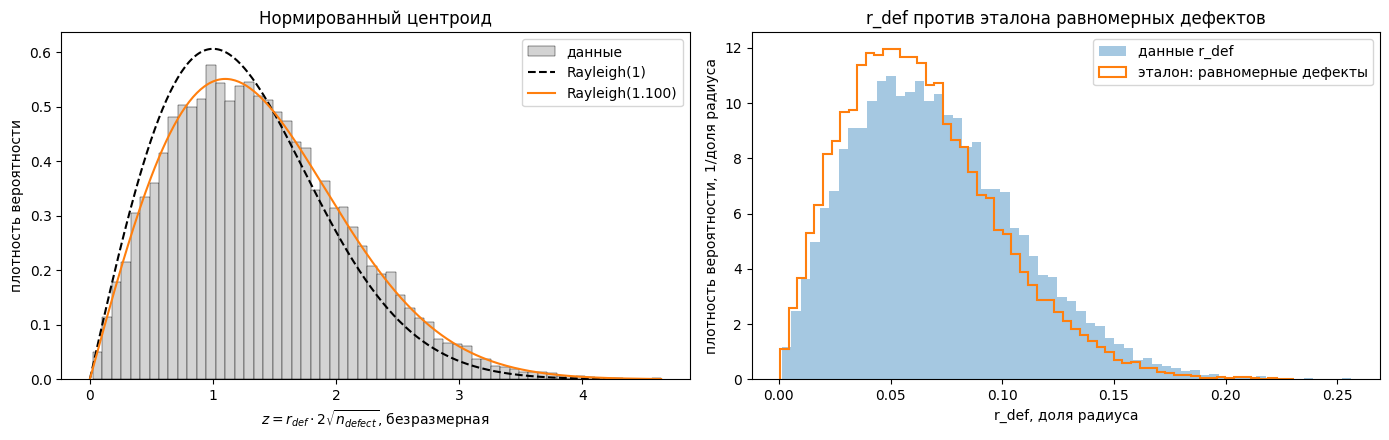

In [14]:
# нормированный центроид z = r_def * 2*sqrt(n_defect): при равномерных дефектах ~ Rayleigh(1)
z = (x * 2 * np.sqrt(kd)).to_numpy()
_, s_z = stats.rayleigh.fit(z, floc=0)
# эталонная смесь: для каждой пластины Rayleigh(1/(2*sqrt(k_i)))
ref = rng.rayleigh(1 / (2 * np.sqrt(kd.to_numpy())))
print(f"z: среднее = {z.mean():.4f} (Rayleigh(1): {np.sqrt(np.pi / 2):.4f}), sigma ММП = {s_z:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
gz = np.linspace(0, z.max(), 300)
axes[0].hist(z, bins=60, density=True, color="lightgray", edgecolor="k", linewidth=0.3, label="данные")
axes[0].plot(gz, stats.rayleigh.pdf(gz), "k--", label="Rayleigh(1)")
axes[0].plot(gz, stats.rayleigh.pdf(gz, scale=s_z), "C1", label=f"Rayleigh({s_z:.3f})")
axes[0].set_xlabel(r"$z = r_{def}\cdot 2\sqrt{n_{defect}}$, безразмерная")
axes[0].set_ylabel("плотность вероятности")
axes[0].set_title("Нормированный центроид")
axes[0].legend()
axes[1].hist(xv, bins=60, density=True, histtype="stepfilled", alpha=0.4, label="данные r_def")
axes[1].hist(ref, bins=60, density=True, histtype="step", lw=1.5, label="эталон: равномерные дефекты")
axes[1].set_xlabel("r_def, доля радиуса")
axes[1].set_ylabel("плотность вероятности, 1/доля радиуса")
axes[1].set_title("r_def против эталона равномерных дефектов")
axes[1].legend()
plt.tight_layout()
plt.show()

#### Математическая база

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Математическая база (PDF, параметры, моменты беты, Рэлея, Вейбулла; почему центроид ~ Рэлей; литература) -->

#### Нормализация

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Нормализация (зачем нужна, что изменилось) -->

In [15]:
x_bc, lam_bc = stats.boxcox(xv)
print(f"Бокс-Кокс: lambda = {lam_bc:.4f}")
transforms = {
    "исходные": xv,
    "z-score": (xv - xv.mean()) / xv.std(ddof=1),
    "логит": np.log(xc / (1 - xc)),
    "Бокс-Кокс": x_bc,
}
pd.DataFrame({name: {"асимметрия": stats.skew(t), "эксцесс (избыточный)": stats.kurtosis(t)}
              for name, t in transforms.items()}).T.round(4)

Бокс-Кокс: lambda = 0.5187


,асимметрия,эксцесс (избыточный)
исходные,0.6605,0.3417
z-score,0.6605,0.3417
логит,-0.9578,1.5965
Бокс-Кокс,-0.0363,-0.2608


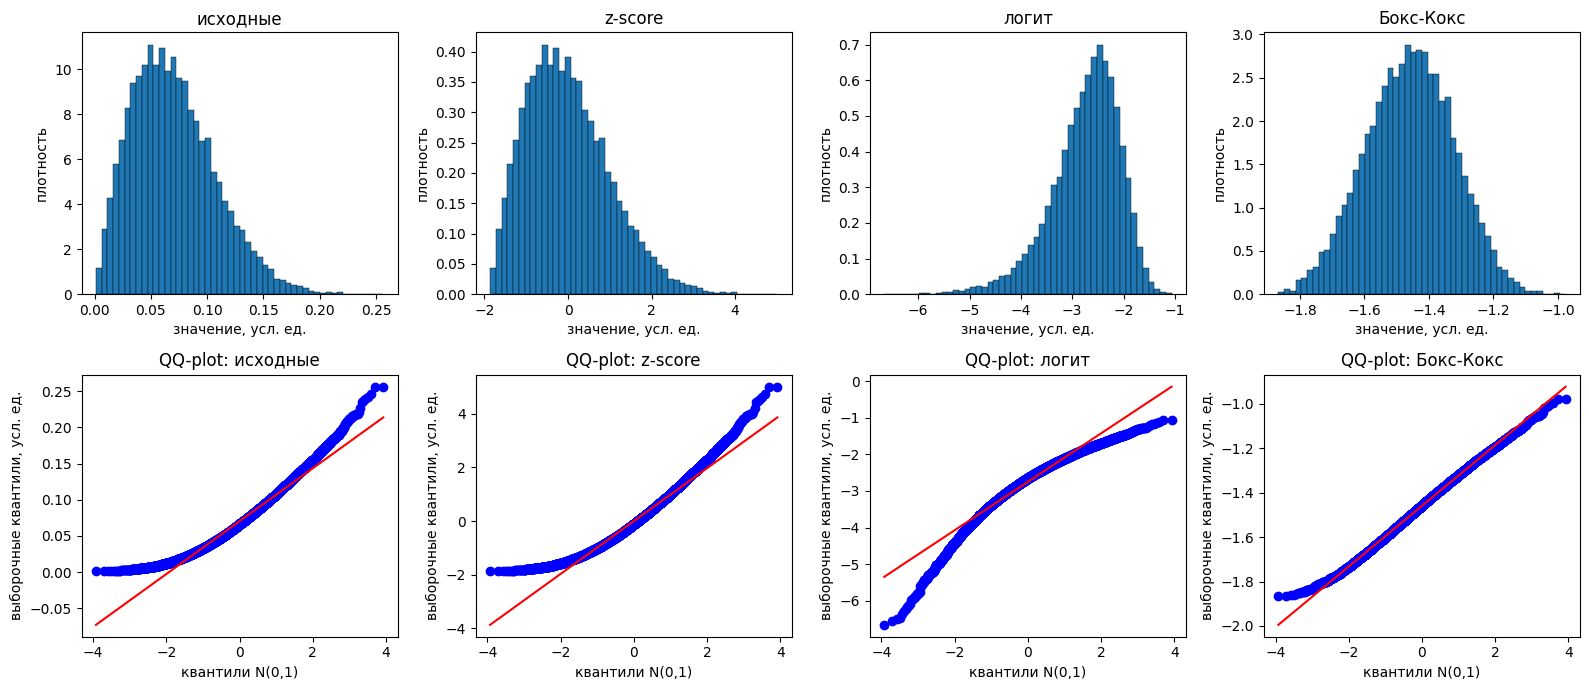

In [16]:
fig, axes = plt.subplots(2, len(transforms), figsize=(16, 7))
for j, (name, t) in enumerate(transforms.items()):
    axes[0, j].hist(t, bins=50, density=True, edgecolor="k", linewidth=0.3)
    axes[0, j].set_title(name)
    axes[0, j].set_xlabel("значение, усл. ед.")
    axes[0, j].set_ylabel("плотность")
    stats.probplot(t, dist="norm", plot=axes[1, j])
    axes[1, j].set_title(f"QQ-plot: {name}")
    axes[1, j].set_xlabel("квантили N(0,1)")
    axes[1, j].set_ylabel("выборочные квантили, усл. ед.")
plt.tight_layout()
plt.show()